# ML Mini Project – Titanic Survival Prediction (Logistic Regression)
**Problem Statement:** Use the Titanic dataset to predict whether a passenger survived, using exploratory data analysis, preprocessing and a Logistic Regression classifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('titanic_data.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## Exploratory Data Analysis

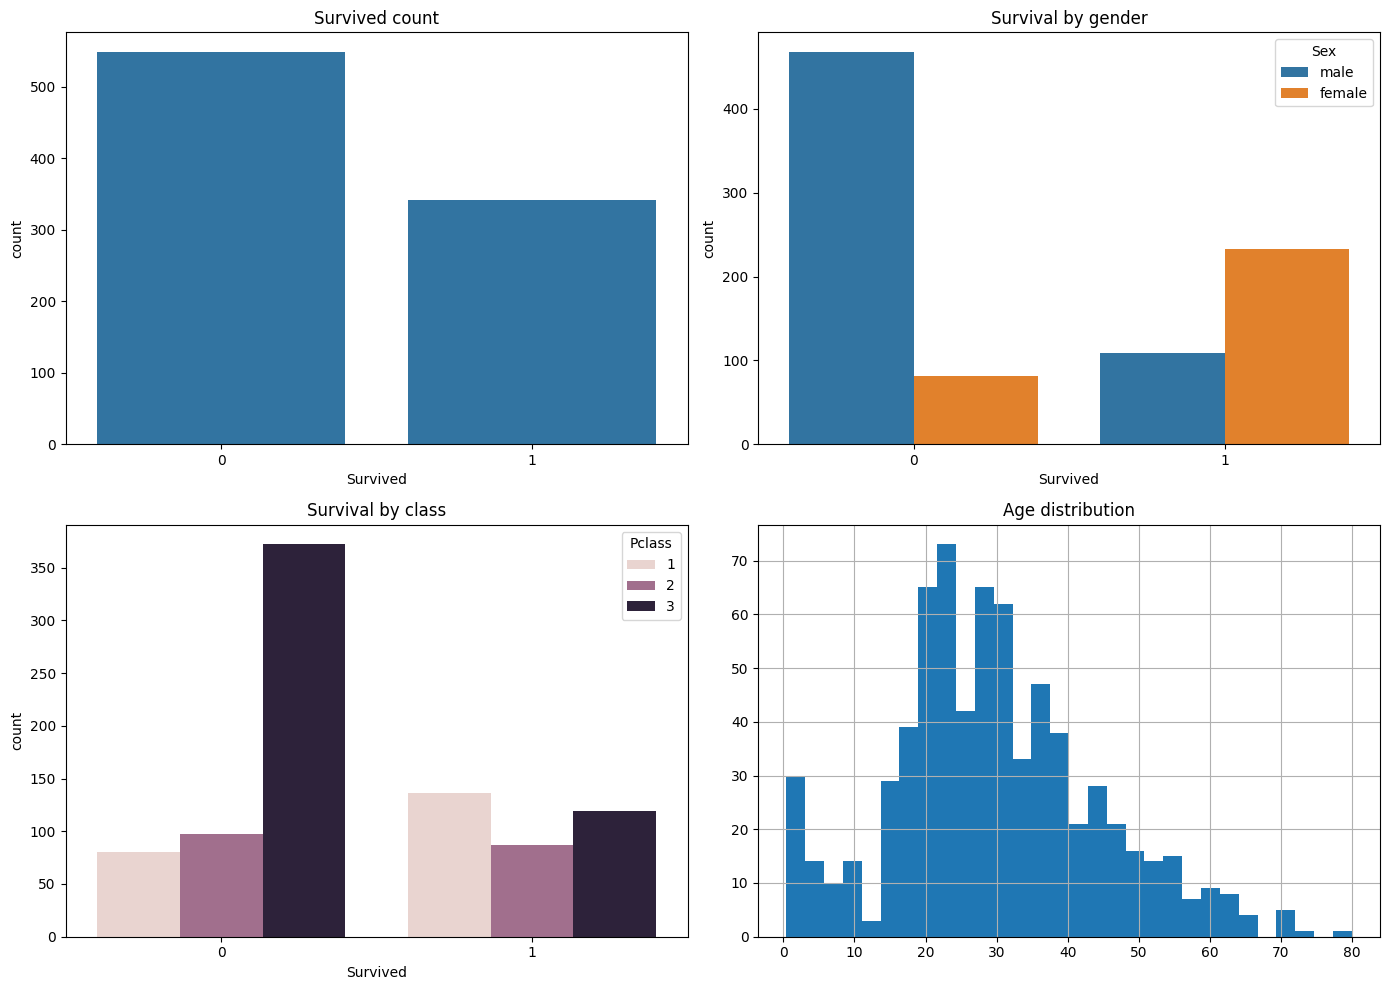

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(x='Survived', data=df, ax=axes[0, 0]).set_title('Survived count')
sns.countplot(x='Survived', hue='Sex', data=df, ax=axes[0, 1]).set_title('Survival by gender')
sns.countplot(x='Survived', hue='Pclass', data=df, ax=axes[1, 0]).set_title('Survival by class')
df['Age'].hist(bins=30, ax=axes[1, 1]); axes[1, 1].set_title('Age distribution')
plt.tight_layout(); plt.show()

## Preprocessing

In [5]:
data = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data = pd.get_dummies(data, columns=['Embarked'], drop_first=True).astype(float)
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0.0,3.0,0.0,22.0,1.0,0.0,7.2500,0.0,1.0
1,1.0,1.0,1.0,38.0,1.0,0.0,71.2833,0.0,0.0
2,1.0,3.0,1.0,26.0,0.0,0.0,7.9250,0.0,1.0
3,1.0,1.0,1.0,35.0,1.0,0.0,53.1000,0.0,1.0
4,0.0,3.0,0.0,35.0,0.0,0.0,8.0500,0.0,1.0


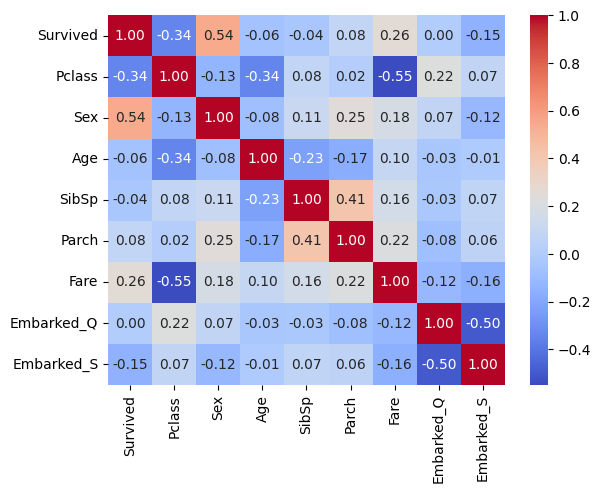

In [6]:
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

In [7]:
X = data.drop(columns=['Survived'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Model

Logistic Regression accuracy: 0.8100558659217877
              precision    recall  f1-score   support

         0.0       0.83      0.86      0.84       105
         1.0       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



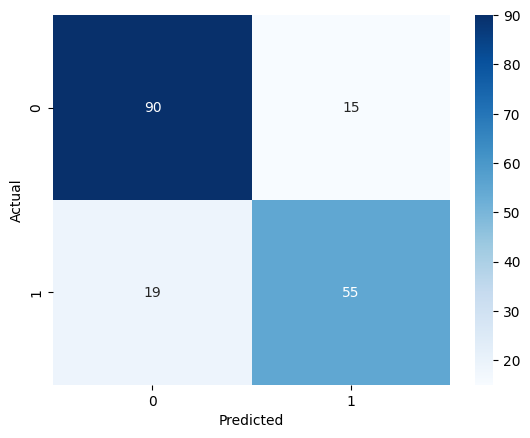

In [8]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)
print('Logistic Regression accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

In [9]:
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
print('Random Forest accuracy:', accuracy_score(y_test, rf.predict(X_test)))

Random Forest accuracy: 0.7988826815642458


**Conclusion:** Gender and passenger class are the strongest predictors; females and 1st-class passengers had higher survival rates. Logistic Regression gives ~80% accuracy.